# Tải thư viện

In [1]:
!pip install pandas_datareader --quiet

# Import thư viện

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_datareader.data as web
from datetime import datetime

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
plt.style.use('seaborn-v0_8-darkgrid')

print("Pandas version:", pd.__version__)

Pandas version: 2.2.3


# Tải dữ liệu từ FRED

data link: [https://fred.stlouisfed.org/series/LTOTALNSA](https://fred.stlouisfed.org/series/LTOTALNSA)

In [3]:
# Tải dữ liệu Light Vehicle Sales (LAUTOSA) từ FRED
start = datetime(2010, 1, 1)
end = datetime(2024, 12, 31)

df = web.DataReader('LAUTOSA', 'fred', start, end)

print("Kiểu dữ liệu:\n", df.dtypes)
print("\n5 dòng đầu:\n", df.head())
print("\nKích thước:", df.shape)

Kiểu dữ liệu:
 LAUTOSA    float64
dtype: object

5 dòng đầu:
             LAUTOSA
DATE               
2010-01-01    5.417
2010-02-01    5.097
2010-03-01    5.632
2010-04-01    5.484
2010-05-01    5.724

Kích thước: (180, 1)


# Parse ngày và đặt làm index

In [4]:
# Đảm bảo index là DatetimeIndex
df.index = pd.to_datetime(df.index)
df.index.name = 'DATE'

# Sắp xếp theo thời gian (quan trọng cho shift/rolling)
df = df.sort_index()

print("Kiểu index:", type(df.index))
print("Index là DatetimeIndex?", isinstance(df.index, pd.DatetimeIndex))
print("\n5 dòng đầu:\n", df.head())

Kiểu index: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Index là DatetimeIndex? True

5 dòng đầu:
             LAUTOSA
DATE               
2010-01-01    5.417
2010-02-01    5.097
2010-03-01    5.632
2010-04-01    5.484
2010-05-01    5.724


# Tạo dải ngày với `pd.date_range()` — tần suất D, W, M

In [5]:
# Tần suất ngày (D)
daily = pd.date_range(start='2024-01-01', periods=10, freq='D')
print("=== Daily (D) ===")
print(daily)

# Tần suất tuần (W) - mặc định kết thúc Chủ nhật
weekly = pd.date_range(start='2024-01-01', periods=6, freq='W')
print("\n=== Weekly (W) ===")
print(weekly)

# Tần suất tuần kết thúc thứ Sáu (W-FRI)
weekly_fri = pd.date_range(start='2024-01-01', periods=6, freq='W-FRI')
print("\n=== Weekly (W-FRI) ===")
print(weekly_fri)

# Tần suất tháng (M) - ngày cuối tháng
monthly = pd.date_range(start='2024-01-01', periods=6, freq='M')
print("\n=== Monthly (M) ===")
print(monthly)

# Tần suất quý (Q) - ngày cuối quý
quarterly = pd.date_range(start='2024-01-01', periods=4, freq='Q')
print("\n=== Quarterly (Q) ===")
print(quarterly)

=== Daily (D) ===
DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05', '2024-01-06', '2024-01-07',
               '2024-01-08', '2024-01-09', '2024-01-10'],
              dtype='datetime64[ns]', freq='D')

=== Weekly (W) ===
DatetimeIndex(['2024-01-07', '2024-01-14', '2024-01-21', '2024-01-28', '2024-02-04', '2024-02-11'], dtype='datetime64[ns]', freq='W-SUN')

=== Weekly (W-FRI) ===
DatetimeIndex(['2024-01-05', '2024-01-12', '2024-01-19', '2024-01-26', '2024-02-02', '2024-02-09'], dtype='datetime64[ns]', freq='W-FRI')

=== Monthly (M) ===
DatetimeIndex(['2024-01-31', '2024-02-29', '2024-03-31', '2024-04-30', '2024-05-31', '2024-06-30'], dtype='datetime64[ns]', freq='ME')

=== Quarterly (Q) ===
DatetimeIndex(['2024-03-31', '2024-06-30', '2024-09-30', '2024-12-31'], dtype='datetime64[ns]', freq='QE-DEC')


/tmp/ipykernel_4021/1208439347.py:17: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = pd.date_range(start='2024-01-01', periods=6, freq='M')
/tmp/ipykernel_4021/1208439347.py:22: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  quarterly = pd.date_range(start='2024-01-01', periods=4, freq='Q')


# Resample về tháng và quý

In [6]:
# Dữ liệu LAUTOSA vốn ở tần suất tháng
# Resample về tháng (tổng)
monthly_resampled = df['LAUTOSA'].resample('ME').sum()

# Resample về quý (tổng doanh số trong quý)
quarterly_resampled = df['LAUTOSA'].resample('QE').sum()

print("=== Monthly (5 dòng đầu) ===")
print(monthly_resampled.head())

print("\n=== Quarterly (5 dòng đầu) ===")
print(quarterly_resampled.head())

print("\nSố kỳ monthly:", len(monthly_resampled))
print("Số kỳ quarterly:", len(quarterly_resampled))

=== Monthly (5 dòng đầu) ===
DATE
2010-01-31    5.417
2010-02-28    5.097
2010-03-31    5.632
2010-04-30    5.484
2010-05-31    5.724
Freq: ME, Name: LAUTOSA, dtype: float64

=== Quarterly (5 dòng đầu) ===
DATE
2010-03-31    16.146
2010-06-30    16.843
2010-09-30    17.283
2010-12-31    17.356
2011-03-31    18.591
Freq: QE-DEC, Name: LAUTOSA, dtype: float64

Số kỳ monthly: 180
Số kỳ quarterly: 60


# Shift và Diff (chênh lệch kỳ trước)

In [7]:
# Tạo bản sao để thao tác
ts = df.copy()

# Shift 1 kỳ
ts['lag_1'] = ts['LAUTOSA'].shift(1)

# Chênh lệch so với kỳ trước
ts['diff_1'] = ts['LAUTOSA'].diff(1)

# Phần trăm thay đổi
ts['pct_change'] = ts['LAUTOSA'].pct_change() * 100

print(ts[['LAUTOSA', 'lag_1', 'diff_1', 'pct_change']].head(10))

            LAUTOSA  lag_1  diff_1  pct_change
DATE                                          
2010-01-01    5.417    NaN     NaN         NaN
2010-02-01    5.097  5.417  -0.320   -5.907329
2010-03-01    5.632  5.097   0.535   10.496370
2010-04-01    5.484  5.632  -0.148   -2.627841
2010-05-01    5.724  5.484   0.240    4.376368
2010-06-01    5.635  5.724  -0.089   -1.554857
2010-07-01    5.738  5.635   0.103    1.827862
2010-08-01    5.786  5.738   0.048    0.836528
2010-09-01    5.759  5.786  -0.027   -0.466644
2010-10-01    5.764  5.759   0.005    0.086821


# Rolling mean (trung bình trượt)

In [8]:
# Trung bình trượt 12 tháng
ts['rolling_12'] = ts['LAUTOSA'].rolling(window=12).mean()

# Trung bình trượt 3 tháng (ngắn hạn)
ts['rolling_3'] = ts['LAUTOSA'].rolling(window=3).mean()

print(ts[['LAUTOSA', 'rolling_3', 'rolling_12']].tail(15))

            LAUTOSA  rolling_3  rolling_12
DATE                                      
2023-10-01    3.027   3.108667    3.084000
2023-11-01    3.162   3.127667    3.089417
2023-12-01    3.100   3.096333    3.116583
2024-01-01    2.997   3.086333    3.108250
2024-02-01    2.984   3.027000    3.110667
2024-03-01    2.932   2.971000    3.103250
2024-04-01    2.994   2.970000    3.083000
2024-05-01    2.977   2.967667    3.072917
2024-06-01    2.819   2.930000    3.040833
2024-07-01    2.983   2.926333    3.022833
2024-08-01    2.927   2.909667    3.008000
2024-09-01    3.012   2.974000    2.992833
2024-10-01    3.073   3.004000    2.996667
2024-11-01    3.073   3.052667    2.989250
2024-12-01    2.957   3.034333    2.977333


# Vẽ biểu đồ chuỗi gốc + rolling mean

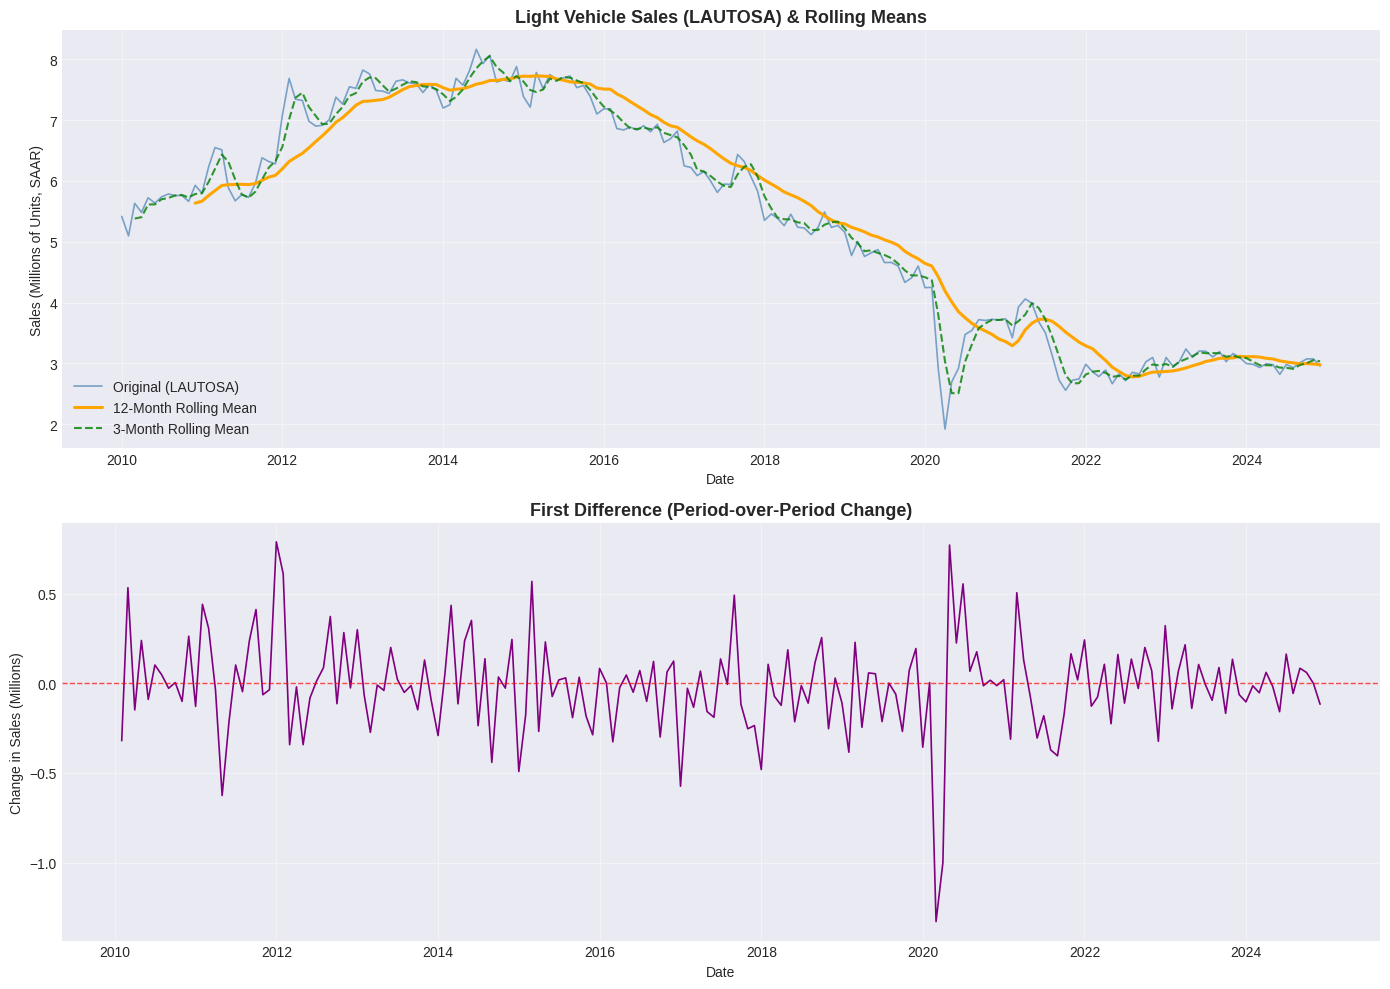

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# --- Biểu đồ 1: Chuỗi gốc + rolling mean ---
axes[0].plot(ts.index, ts['LAUTOSA'], label='Original (LAUTOSA)',
             color='steelblue', alpha=0.7, linewidth=1.2)
axes[0].plot(ts.index, ts['rolling_12'], label='12-Month Rolling Mean',
             color='orange', linewidth=2.2)
axes[0].plot(ts.index, ts['rolling_3'], label='3-Month Rolling Mean',
             color='green', linewidth=1.5, linestyle='--', alpha=0.8)
axes[0].set_title('Light Vehicle Sales (LAUTOSA) & Rolling Means', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Sales (Millions of Units, SAAR)')
axes[0].legend(loc='lower left')
axes[0].grid(True, alpha=0.4)

# --- Biểu đồ 2: Differenced series (đã làm dừng) ---
axes[1].plot(ts.index, ts['diff_1'], color='purple', linewidth=1.2)
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7)
axes[1].set_title('First Difference (Period-over-Period Change)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Change in Sales (Millions)')
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# So sánh Monthly vs Quarterly

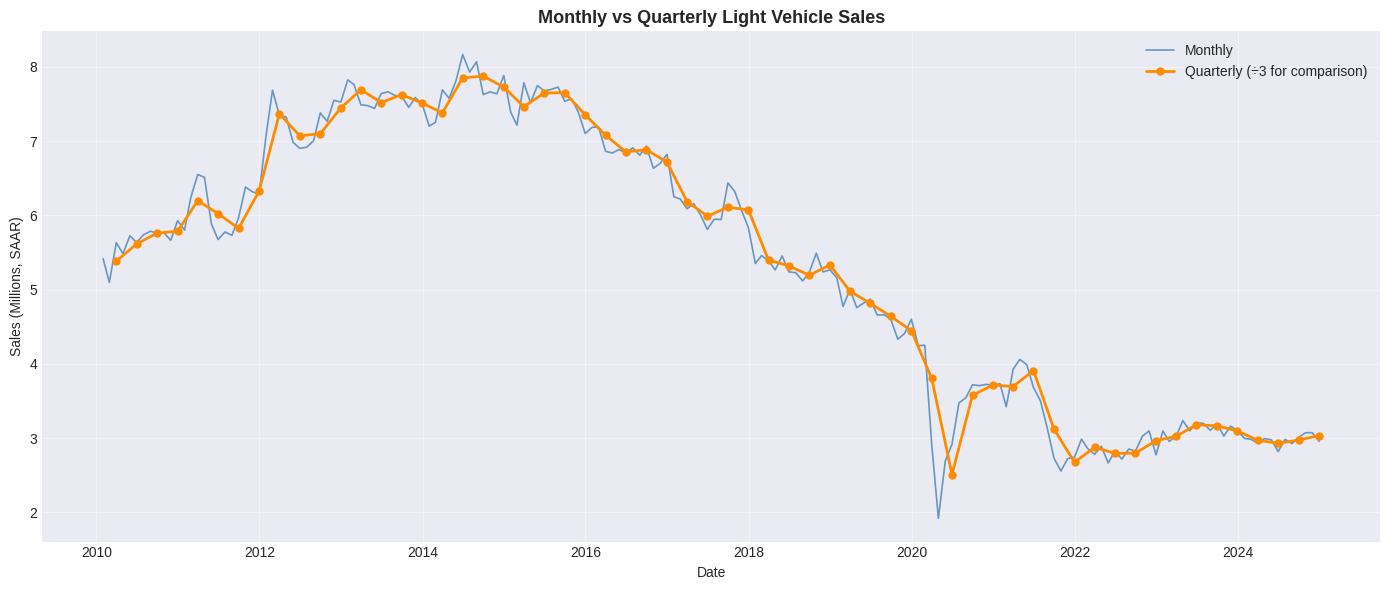

In [10]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(monthly_resampled.index, monthly_resampled, label='Monthly',
        color='steelblue', linewidth=1.2, alpha=0.8)

# Scale quarterly về cùng trục (chia 3) để dễ so sánh
ax.plot(quarterly_resampled.index, quarterly_resampled / 3,
        label='Quarterly (÷3 for comparison)', color='darkorange',
        linewidth=2, marker='o', markersize=5)

ax.set_title('Monthly vs Quarterly Light Vehicle Sales', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Sales (Millions, SAAR)')
ax.legend()
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# Kiểm tra tính dừng (stationarity) trực quan

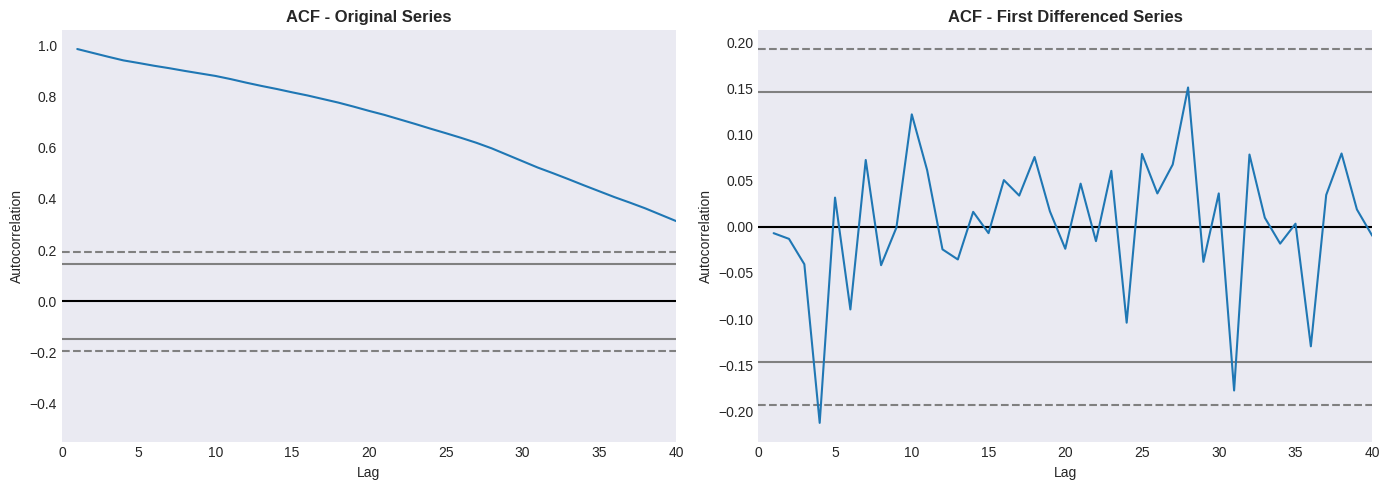

In [11]:
from pandas.plotting import autocorrelation_plot

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ACF của chuỗi gốc
autocorrelation_plot(ts['LAUTOSA'].dropna(), ax=axes[0])
axes[0].set_title('ACF - Original Series', fontweight='bold')
axes[0].set_xlim(0, 40)

# ACF của chuỗi đã diff
autocorrelation_plot(ts['diff_1'].dropna(), ax=axes[1])
axes[1].set_title('ACF - First Differenced Series', fontweight='bold')
axes[1].set_xlim(0, 40)

plt.tight_layout()
plt.show()